## Домашка 3

#### *«Ты понимаешь, что это значит? Это значит, что эта пакость не работает!» — Назад в будущее*

Эта домашка про метрики в a/b-тестировании. За неё можно получить максимум 12 баллов. 

**Дедлайны**  
Мягкий дедлайн: 04.10.2026 23:59 по МСК.   
Жесткий дедлайн: 11.10.2026 23:59 по МСК.  

Штраф за сдачу после мягкого дедлайна: –20% от набранного балла.   
После жесткого дедлайна работы не принимаются.   

**Правила сдачи**   
Задание выполняется самостоятельно, списывания не допускаются. При обнаружении одинаковых работ балл за задание анулируется у всех студентов, вне зависимости от того, кто у кого списал.    

**Использование ИИ**
- Использование генеративных моделей для написания кода допустимо при следующих условиях: сгенерированный фрагмент прочитан, адаптирован под условие задачи и данные, вы способны объяснить каждую его строку. Решение, полученное путем передачи модели формулировки задания целиком и прямого копирования ответа в ячейку ноутбука без содержательной переработки, оценивается в 0 баллов за это задание.
- Ответы на текстовые вопросы (описание поведения графика, интерпретация метрики, формулировка гипотез и т.п.) должны быть написаны вами самостоятельно в markdown-ячейках. Использование генеративных моделей для ответа на текстовые вопросы приводит к аннулированию всей работы, а не отдельного задания: интерпретация результатов — главный проверяемый в курсе навык, передача ее ИИ лишает нас возможности оценить, насколько хорошо вы усвоили материал.
- Если генеративная модель использовалась при решении, в конце ноутбука в отдельной markdown-ячейке укажите: номера заданий, при работе над которыми она применялась, использованную модель (с версией) и текст промтов. При обоснованном подозрении на использование ИИ, не отраженное в этом разделе, работа аннулируется целиком независимо от того, к какой части заданий относится подозрение.

#### **Как сдать домашку?**
1. Создайте закрытый репозиторий в личном гитхаб аккаунте для нашего предмета. 
2. Пригласите в него своего ассистента — распределение по ассистентам и их гитхаб юзернеймы находятся в ведомости на листочке нашей дисциплины. Это можно сделать в настройках через раздел Collaborators and teams, уровень доступа ассистента должен быть Write.
3. Скачайте этот ноутбук и решите задания (локально или в Google Colab).
4. В репозитории предмета создайте ветку с номером ДЗ (например hw_3). В эту ветку запушьте .ipynb-файл с решением. Создайте pull request и добавьте в него ассистента как Reviewer. В этот же PR можете пушить сколько угодно изменений, будем смотреть на последнюю версию до наступления дедлайна.
5. Ссылку на PR продублируйте в форме сдачи (форма будет доступна на LMS Karpov Courses и в Телеграм-канале курса).

Пункты 1-2 проделываются один раз. Если вы прошли эти шаги при сдаче других домашек, повторять их не нужно, начинайте сразу с пункта 3. 

**Внимание**: Если вы работаете в Google Colab, также скачивайте .ipynb файл и публикуйте его в репозитории. Ссылки на Colab к сдаче не принимаются.


Все датасеты, с которыми предлагается работать в домашних заданиях, взяты из открытых источников или сгенерированы. Любые паттерны, найденные вне заданной канвы решения, являются случайными и не несут в себе смысла или инсайта.

[Данные](https://github.com/brezhnevaan/hse_product_metrics_course/releases/download/datasets_for_hw/hw_3_data.zip)

In [6]:
import pandas as pd
import numpy as np
from scipy.stats import norm, pearsonr
import math

### Warm up

#### 1. Сопоставьте тип эксперимента с продуктовым изменением — 2 балла

a) По-юзерный A/B тест  
b) Свитчбек (по времени)   
c) Региональный A/B тест


1. Новая логика выдачи контента на главной в стриминговом сервисе фильмов и сериалов.
2. Запуск динамического ценообразования в сервисе доставки еды.
3. Тестирование push-уведомления о брошенной корзине в e-commerce приложении.
4. Раскатка в сервисе такси через эксперимент новой схемы комиссий для водителей (старт с одного города).
5. Добавление ипотечного калькулятора с точкой входа в Новостройки на главной сервиса объявлений Недвижимости.
6. Изменение SLA времени доставки в сервисе курьерской доставки (старт с одного города).

### 1. a)
### 2. b)
### 3. a)
### 4. c)
### 5. a)
### 6. c)

### Case Study. Дизайн эксперимента в сервисе объявлений жилой недвижимости 🏡

**Легенда**  
Вы работаете продуктовым аналитиком в сервисе объявлений жилой недвижимости. Платформа позволяет пользователям размещать объявления о продаже и аренде жилья (как частным лицам, так и застройщикам), а другим — просматривать и контактировать / оставлять заявки по объявлениям.    
Ваша команда "Новостройки" хочет разместить на главной ипотечный калькулятор с точкой входа напрямую в свой раздел. Цель — увеличить число заявок.

**Гипотеза** — размещение ипотечного калькулятора на главной сервиса увеличит долю пользователей, оставивших заявку в Новостройках, как минимум на 15%, при этом не ухудшит аналогичные метрики в других разделах (Аренда, Вторичка) более чем на 3%.

$$
\Delta_{\mathrm{rel}}=\left(\frac{p_t-p_c}{p_c}\right)\times 100\% \quad \text{(формула эффекта)}
$$

**Ограничения** — вы не можете держать главную в тесте больше 14 дней из-за запланированного календаря экспериментов с другими командами.

**Набор метрик для дизайна.**   
Target — доля пользователей с заполненной заявкой на звонок (Новостройки).   

Guardrails:
- доля пользователей с контактом по объявлению Аренды;
- доля пользователей с контактом по объявлению Вторички;
- доля пользователей с контактом по объявлению из любой категории (подумайте, зачем нужна эта метрика? от какой ловушки она защищает?).   

Informative:
- доля пользователей, перешедших с главной в раздел Аренды;
- доля пользователей, перешедших с главной в раздел Вторички;
- доля пользователей, перешедших с главной в раздел Новостроек;
- доля пользователей с переходами в список объявлений по навигации на главной.

Все доли рассчитываются от набранного объема пользователей в каждой из групп. Пользователи попадают в exposure сразу при посещении главной.

**Для расчетов метрик используйте следующие ивенты:**
- Для target и guardrails — contact_submit.
- Для informative — list_view и source==main_nav.

*В рамках такого эксперимента также имеет смысл смотреть на среднее число контактов / заявок по каждому из разделов и в общем, а не просто на бинарные метрики. Но в данном задании мы сосредоточимся на долях, чтобы не раздувать алгоритм расчета до полного реалистичного пресета метрик.*

In [8]:
df_logs = pd.read_csv('hw_3_events_data.csv')
df_logs.head()

,timestamp,user_id,session_id,event,category,source,listing_id
0,2025-06-01 00:00:00,114227,8828585581,main_view,none,none,NaN
1,2025-06-01 00:00:00,212987,8591655166,main_view,none,none,NaN
2,2025-06-01 00:00:00,1413962,2533393268,add_fav,rent_long,other,992874562.0
3,2025-06-01 00:00:00,1221850,2060698550,main_view,none,none,NaN
4,2025-06-01 00:00:00,31469,6550065912,main_view,none,none,NaN


In [120]:
df_exps = pd.read_csv('hw_3_experimens_history.csv')
df_exps.head()

,exp_id,days,target_contact_effect_rel,target_contact_p_value,target_contact_p0,target_contact_effect_abs,proxy_card_effect_rel,proxy_card_p_value,proxy_card_p0,proxy_card_effect_abs,proxy_fav_effect_rel,proxy_fav_p_value,proxy_fav_p0,proxy_fav_effect_abs,proxy_form_effect_rel,proxy_form_p_value,proxy_form_p0,proxy_form_effect_abs
0,3937,7,0.000067,0.448527,0.000382,2.562909e-08,0.000814,0.254909,0.014527,0.000012,0.014880,0.443100,0.004335,0.000065,0.054000,0.200074,0.000782,0.000042
1,2806,7,0.000053,0.353007,0.000339,1.793707e-08,0.025588,0.002390,0.012604,0.000323,0.055000,0.007806,0.004289,0.000236,0.042542,0.077772,0.000687,0.000029
2,3457,7,0.000036,0.397718,0.000353,1.255839e-08,0.010437,0.171633,0.013020,0.000136,0.007892,0.486577,0.004187,0.000033,0.028638,0.385118,0.000718,0.000021
3,1002,7,0.000032,0.266510,0.000388,1.246465e-08,0.015525,0.001215,0.012697,0.000197,0.045051,0.000516,0.004062,0.000183,0.025849,0.164273,0.000735,0.000019
4,9070,7,0.000046,0.461855,0.000377,1.722521e-08,0.011572,0.217843,0.013902,0.000161,0.010127,0.317622,0.004349,0.000044,0.036751,0.236595,0.000786,0.000029


Описание данных hw_3_events_data:

- timestamp — дата-время взаимодействия с контентом
- user_id — уникальный идентификатор пользователя
- session_id – уникальный идентификатор сессии
- event — тип события
- category — категория, в которой произошло событие (не приходит для главной)
- source — источник перехода на страницу
- listing_id – уникальный идентификатор объявления

Описание данных hw_3_experimens_history (это история экспериментов именно в разделе Новостройки):

- exp_id — уникальный идентификатор эксперимента
- days — длительность теста
- target_contact_effect_rel — относительный эффект на таргет метрике
- target_contact_p_value — p-value полученного результата для таргет метрики
- target_contact_p0 — значение конверсии таргет метрики в контроле
- target_contact_effect_abs — абсолютный эффект на таргет метрике
- proxy_card_effect_rel — относительный эффект на конверсии просмотра карточки объявления
- proxy_card_p_value — p-value полученного результата для конверсии просмотра карточки объявления
- proxy_card_p0 — значение конверсии просмотра карточки объявления в контроле
- proxy_card_effect_abs — абсолютный эффект на конверсии просмотра карточки объявления
- proxy_fav_effect_rel — относительный эффект на конверсии добавления объявления в избранное
- proxy_fav_p_value — p-value полученного результата для конверсии добавления объявления в избранное
- proxy_fav_p0 — значение конверсии добавления объявления в избранное в контроле
- proxy_fav_effect_abs – абсолютный эффект на конверсии добавления объявления в избранное
- proxy_form_effect_rel — относительный эффект на конверсии открытия формы заявки на звонок по объявлению
- proxy_form_p_value — p-value полученного результата для конверсии открытия формы заявки на звонок по объявлению
- proxy_form_p0 — значение конверсии открытия формы заявки на звонок по объявлению в контроле
- proxy_form_effect_abs — абсолютный эффект на конверсии открытия формы заявки на звонок по объявлению

#### 2. Рассчитайте количество дней, необходимое для детектирования заявленных в гипотезе эффектов (target и guardrails-метрики) — 2 балла
Здесь и далее используйте для расчетов значение alpha = 0.01 (делаем поправку на принятие решения по набору метрик) и beta = 0.2. А также двусторонний критерий — мы заранее не знаем, куда двинутся метрики, поэтому хотим учесть и противоположные эффекты.  

Для метрики "доля пользователей с контактом по объявлению из любой категории" также используйте эффект в 3%.

In [10]:
alpha = 0.01
beta = 0.2

In [12]:
df_logs.describe(include = 'object')

,timestamp,event,category,source
count,8671885,8671885,8671885,8671885
unique,1208460,7,5,3
top,2025-06-14 07:27:32,main_view,none,none
freq,27,4427608,4427608,4427608


In [13]:
df_logs.dtypes

timestamp      object
user_id         int64
session_id      int64
event          object
category       object
source         object
listing_id    float64
dtype: object

In [14]:
df_logs['timestamp']= pd.to_datetime(df_logs['timestamp']).dt.date
df_logs.dtypes

timestamp      object
user_id         int64
session_id      int64
event          object
category       object
source         object
listing_id    float64
dtype: object

In [15]:
df_logs.user_id.nunique()

1781124

In [16]:
def sample_size_mean(p, mde, alpha, power, two_sided=True):

    var = p*(1-p)

    if two_sided:
        z_alpha = norm.ppf(1 - alpha/2)
    else:
        z_alpha = norm.ppf(1 - alpha)
    z_beta = norm.ppf(power)

    n = (2 * var * (z_alpha + z_beta) ** 2) / (mde ** 2)

    return int(np.ceil(n))

In [17]:
df_logs['category'].unique()

array(['none', 'rent_long', 'secondary', 'newbuilds', 'rent_daily'],
      dtype=object)

In [18]:
exposed_id = set(df_logs['user_id'][df_logs['event'] == 'main_view'])
len(exposed_id)

1781124

In [19]:
contacts = df_logs[(df_logs['event'] == 'contact_submit') & (df_logs['user_id'].isin(exposed_id))]
len(contacts['user_id'])

105705

### Target — доля пользователей с заполненной заявкой на звонок (Новостройки).

In [23]:
p_target = contacts['user_id'][(contacts['category']=='newbuilds')].nunique() / len(exposed_id)
p_target

0.00037279830039907387

In [24]:
sample_size_mean(p_target, p_target*0.15, alpha, 1-beta)

2783660

### Доля пользователей с контактом по объявлению Аренды

In [26]:
p_rent = contacts['user_id'][(contacts['category']=='rent_long') | (contacts['category']=='rent_daily')].nunique() / len(exposed_id)
p_rent

0.0433479083994152

### Доля пользователей с контактом по объявлению Вторички

In [32]:
p_secondary = contacts['user_id'][(contacts['category']=='secondary')].nunique() / len(exposed_id)
p_secondary

0.014516114543400684

### Доля пользователей с контактом по любому объявлению

In [34]:
p_any = contacts['user_id'][(contacts['category']=='rent_long') | (contacts['category']=='rent_daily') | (contacts['category']=='secondary') | (contacts['category']=='newbuilds')].nunique() / len(exposed_id)
p_any

0.05739577929442307

In [35]:
first_view = (df_logs[df_logs['event'] == 'main_view'].groupby('user_id')['timestamp'].min())
first_view.index

Index([      2,       3,       4,       5,       6,       7,       8,       9,
            10,      11,
       ...
       1999991, 1999992, 1999993, 1999994, 1999995, 1999996, 1999997, 1999998,
       1999999, 2000000],
      dtype='int64', name='user_id', length=1781124)

In [36]:
first_view.index.nunique()

1781124

In [37]:
cumsum = first_view.value_counts().sort_index().cumsum()
cumsum

timestamp
2025-06-01     317702
2025-06-02     541200
2025-06-03     740053
2025-06-04     916107
2025-06-05    1069387
2025-06-06    1208492
2025-06-07    1338902
2025-06-08    1443539
2025-06-09    1516954
2025-06-10    1583062
2025-06-11    1641170
2025-06-12    1691812
2025-06-13    1738001
2025-06-14    1781124
Name: count, dtype: int64

In [40]:
metrics = {
    'target: заявки Новостройки': (p_target, 0.15),
    'guardrail: Аренда':          (p_rent, 0.03),
    'guardrail: Вторичка':        (p_secondary, 0.03),
    'guardrail: любая категория': (p_any, 0.03),
}
metrics.items()

dict_items([('target: заявки Новостройки', (0.00037279830039907387, 0.15)), ('guardrail: Аренда', (0.0433479083994152, 0.03)), ('guardrail: Вторичка', (0.014516114543400684, 0.03)), ('guardrail: любая категория', (0.05739577929442307, 0.03))])

In [41]:
rows = []
for name, (p, rel) in metrics.items():
    group= sample_size_mean(p, p*rel, alpha, 1 - beta)
    groups = 2*group
    days = (cumsum < groups).sum()+1 
    if days == 15:
        days = np.nan
    rows.append([name, p, rel, group, groups, days])

result = pd.DataFrame(rows, columns=['метрика', 'p', 'отн. эффект', 'n на группу', 'n всего', 'дней'])
result

,метрика,p,отн. эффект,n на группу,n всего,дней
0,target: заявки Новостройки,0.000373,0.15,2783660,5567320,NaN
1,guardrail: Аренда,0.043348,0.03,572767,1145534,6.0
2,guardrail: Вторичка,0.014516,0.03,1761940,3523880,NaN
3,guardrail: любая категория,0.057396,0.03,426228,852456,4.0


In [42]:
print(p_target + p_rent + p_secondary)
print(p_any)

0.058236821243214956
0.05739577929442307


### В итоге защитные метрики не получится прокрасить за 14 дней теста, так как пользователей не наберётся для проведения
### В навостройках слишком маленькая конверсия из главной в оформление заявки
### На аренде и любой категории тест успеет прокраситься, так как у них высокие конверсии

#### 3. Рассчитайте MDE для информативных метрик — 2 балла
В реальности эффекты по информативным критериям, которые мы также хотим включать в пресет метрик, нужно сравнивать на достижимость на основе прошлых экспериментов. Как правило, проделав это упражнение один раз, вы просто сохраняете достижимый трешхолд в базе знаний команды и принимаете решение о включении их в базовый набор. Проверка эффектов для каждого теста не требуется. Однако, стоит делать периодический пересмотр зафиксированных достижимых эффектов, например раз в полгода / год, или при сильных изменениях продукта / рынка.

В данном задании мы с вами не будем опираться на историю тестов, просто потренируемся делать обратный расчет — размера эффекта от заданной длительности (14 дней).

*Для числителя используйте только ивенты с источником main_nav*

In [51]:
int(len(exposed_id) / 2)

890562

In [52]:
nav = df_logs[(df_logs['event'] == 'list_view') & (df_logs['source'] == 'main_nav') & (df_logs['user_id'].isin(exposed_id))]
nav

,timestamp,user_id,session_id,event,category,source,listing_id
20,2025-06-01,706540,5951252665,list_view,secondary,main_nav,NaN
22,2025-06-01,1092601,4312158447,list_view,rent_long,main_nav,NaN
29,2025-06-01,506619,6465032608,list_view,newbuilds,main_nav,NaN
38,2025-06-01,557340,1930252504,list_view,rent_long,main_nav,NaN
59,2025-06-01,10110,6156462292,list_view,rent_daily,main_nav,NaN
...,...,...,...,...,...,...,...
8671852,2025-06-14,1474955,8568605409,list_view,rent_daily,main_nav,NaN
8671857,2025-06-14,60948,2706214481,list_view,rent_long,main_nav,NaN
8671859,2025-06-14,1055620,2408907654,list_view,rent_daily,main_nav,NaN
8671872,2025-06-14,99885,1392565397,list_view,rent_daily,main_nav,NaN


In [83]:
metrics = {
    'rent': ['rent_long', 'rent_daily'],
    'secondary': ['secondary'],
    'newbuilds': ['newbuilds'],
    'any': ['rent_long', 'rent_daily', 'secondary', 'newbuilds']
}
metrics.items()
p_nav = {}
for name, categories in metrics.items():
    p_nav[name] = nav['user_id'][nav['category'].isin(categories)].nunique() / len(exposed_id)
p_nav

{'rent': 0.4150626233771484,
 'secondary': 0.22395689463507312,
 'newbuilds': 0.044574100399522996,
 'any': 0.545932793000375}

In [99]:
def mde_prop(p, n, alpha, power, two_sided=True):
    z_alpha = norm.ppf(1 - alpha / 2) if two_sided else norm.ppf(1 - alpha)
    z_beta = norm.ppf(power)
    mde_abs = (z_alpha + z_beta) * np.sqrt(2 * p * (1 - p) / n)
    return mde_abs, mde_abs / p 

In [101]:
rows = []
for name, p in p_nav.items():
    mde_abs, mde_rel = mde_prop(p, len(exposed_id) / 2, alpha, 1 - beta, two_sided=True)
    rows.append([name, p, mde_abs, mde_rel])
pd.DataFrame(rows, columns = ['Метрика', 'p', 'MDE abs', 'MDE rel'])

,Метрика,p,MDE abs,MDE rel
0,rent,0.415063,0.002523,0.006080
1,secondary,0.223957,0.002135,0.009533
2,newbuilds,0.044574,0.001057,0.023711
3,any,0.545933,0.002550,0.004671


#### 4. Выбираем proxy-метрику (шаг 1) — 2 балла
Стало понятно, что за 14 дней мы не успеем замерить эффект по таргету. Что делать? Можно использовать методы снижения дисперсии, а можно попробовать подобрать proxy-метрику. Давайте реализуем второй вариант.

**Для proxy будем использовать 3-х кандидатов:**
- доля пользователей с просмотром карточки объявления в Новостройках;
- доля пользователей, добавивших в избранное объявление в Новостройках;
- доля пользователей, открывших форму заявки в Новостройках — связь с автором объявления в этом разделе предполагает обратный звонок от офиса продаж, поэтому чтобы сделать событие контакта, релевантное другим разделам, нужно ввести свой номер телефона в форму заявки, расположенную на карточке.

Для каждой из proxy-метрик:
- Рассчитайте MDE для заданной длительности — 14 дней;
- По историческому набору экспериментов постройте диаграмму рассеяния зафиксированных эффектов и длительности тестов (пометьте значимые эффекты).

**Для расчетов метрик используйте следующие ивенты:**
- Для proxy — card_view, add_fav, form_start.

In [126]:
proxy_metrics = {
    'card': 'card_view', 
    'fav': 'add_fav', 
    'form': 'form_start' 
}
row_proxy = []
for name, event in proxy_metrics.items():
    p = df_logs['user_id'][(df_logs['event'] == event) & (df_logs['category'] == 'newbuilds') & (df_logs['user_id'].isin(exposed_id))].nunique() / len(exposed_id)
    mde_abs, mde_rel = mde_prop(p, len(exposed_id) / 2, alpha, 1 - beta, two_sided=True)
    row_proxy.append([name, p, mde_abs, mde_rel])
proxy_mde = pd.DataFrame(row_proxy, columns = ['Метрика', 'p', 'MDE abs', 'MDE rel'])    
proxy_mde

,Метрика,p,MDE abs,MDE rel
0,card,0.013663,0.000595,0.043514
1,fav,0.003959,0.000322,0.081235
2,form,0.000719,0.000137,0.190973


In [137]:
df_exps

,exp_id,days,target_contact_effect_rel,target_contact_p_value,target_contact_p0,target_contact_effect_abs,proxy_card_effect_rel,proxy_card_p_value,proxy_card_p0,proxy_card_effect_abs,proxy_fav_effect_rel,proxy_fav_p_value,proxy_fav_p0,proxy_fav_effect_abs,proxy_form_effect_rel,proxy_form_p_value,proxy_form_p0,proxy_form_effect_abs
0,3937,7,0.000067,0.448527,0.000382,2.562909e-08,0.000814,0.254909,0.014527,0.000012,0.014880,0.443100,0.004335,0.000065,0.054000,0.200074,0.000782,0.000042
1,2806,7,0.000053,0.353007,0.000339,1.793707e-08,0.025588,0.002390,0.012604,0.000323,0.055000,0.007806,0.004289,0.000236,0.042542,0.077772,0.000687,0.000029
2,3457,7,0.000036,0.397718,0.000353,1.255839e-08,0.010437,0.171633,0.013020,0.000136,0.007892,0.486577,0.004187,0.000033,0.028638,0.385118,0.000718,0.000021
3,1002,7,0.000032,0.266510,0.000388,1.246465e-08,0.015525,0.001215,0.012697,0.000197,0.045051,0.000516,0.004062,0.000183,0.025849,0.164273,0.000735,0.000019
4,9070,7,0.000046,0.461855,0.000377,1.722521e-08,0.011572,0.217843,0.013902,0.000161,0.010127,0.317622,0.004349,0.000044,0.036751,0.236595,0.000786,0.000029
5,4504,7,-0.000039,0.479687,0.000343,-1.335593e-08,-0.015000,0.000287,0.012683,-0.000190,-0.008640,0.380702,0.004024,-0.000035,-0.031353,0.270488,0.000728,-0.000023
6,4902,7,0.000081,0.304208,0.000409,3.321012e-08,0.035000,0.000646,0.012634,0.000442,0.018000,0.395971,0.004185,0.000075,0.135000,0.002790,0.000727,0.000098
7,5640,7,0.000038,0.101758,0.000336,1.271483e-08,0.014985,0.154000,0.013375,0.000200,0.008405,0.105775,0.004347,0.000037,0.030502,0.241278,0.000647,0.000020
8,2920,14,-0.117832,0.075904,0.000381,-4.487740e-05,-0.008614,0.008880,0.013584,-0.000117,-0.004791,0.442274,0.003686,-0.000018,-0.115340,0.009822,0.000671,-0.000077
9,1169,14,0.167749,0.123505,0.000348,5.839791e-05,0.012026,0.006465,0.014185,0.000171,0.040040,0.000103,0.003597,0.000144,0.032556,0.427518,0.000706,0.000023


In [143]:
df_exps.days.unique()

array([ 7, 14, 21, 28])

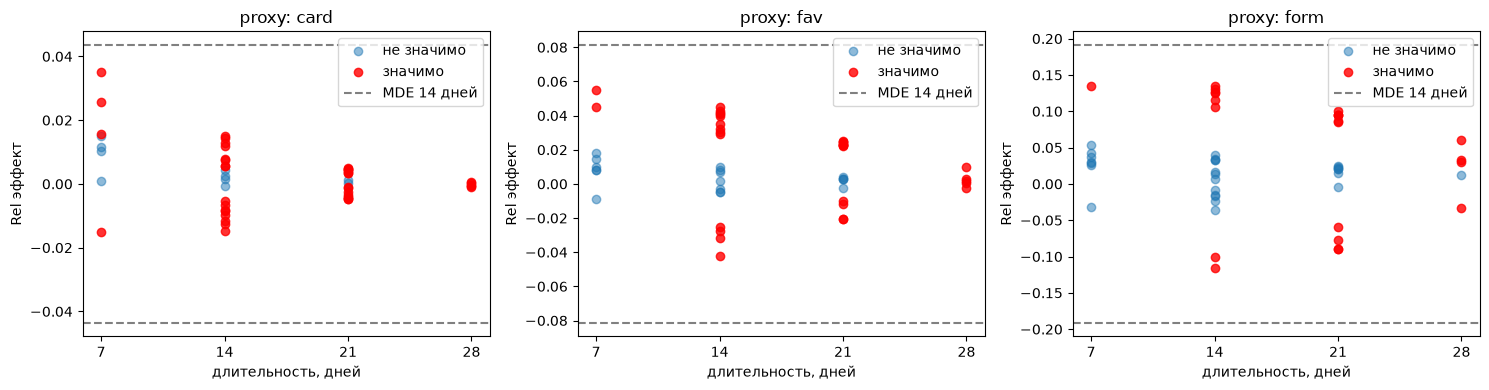

In [199]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

max_df = []
for ax, name in zip(axes, proxy_metrics):
    eff = df_exps[f'proxy_{name}_effect_rel']
    sig = df_exps[f'proxy_{name}_p_value'] < alpha

    ax.scatter(df_exps.loc[~sig, 'days'], eff[~sig], alpha=0.5, label='не значимо')
    ax.scatter(df_exps.loc[sig, 'days'], eff[sig], alpha=0.8, color='red', label='значимо')
    max_df.append([name, df_exps.loc[sig, 'days'], eff[sig]])
    ax.set_xticks(sorted(df_exps['days'].unique()))
    mde = proxy_mde.loc[proxy_mde['Метрика'] == name, 'MDE rel'].iloc[0]
    ax.axhline(mde, linestyle='--', color='gray', label='MDE 14 дней')
    ax.axhline(-mde, linestyle='--', color='gray')

    ax.set_title(f'proxy: {name}')
    ax.set_xlabel('длительность, дней')
    ax.set_ylabel('Rel эффект')
    ax.legend()

plt.tight_layout()
plt.show()

In [201]:
max_df

[['card',
  1      7
  3      7
  5      7
  6      7
  8     14
  9     14
  10    14
  11    14
  12    14
  13    14
  15    14
  16    14
  17    14
  18    14
  19    14
  20    14
  21    14
  22    14
  23    14
  26    14
  29    21
  30    21
  31    21
  32    21
  33    21
  34    21
  35    21
  36    21
  37    21
  38    21
  39    21
  40    21
  42    21
  43    21
  44    21
  45    28
  46    28
  47    28
  48    28
  49    28
  Name: days, dtype: int64,
  1     0.025588
  3     0.015525
  5    -0.015000
  6     0.035000
  8    -0.008614
  9     0.012026
  10   -0.008169
  11   -0.009619
  12    0.015000
  13    0.005733
  15    0.007782
  16   -0.011490
  17   -0.014674
  18   -0.012633
  19   -0.005494
  20    0.007552
  21   -0.006712
  22    0.012737
  23    0.005610
  26    0.014448
  29   -0.001299
  30    0.004693
  31    0.004563
  32    0.005000
  33   -0.001105
  34   -0.004443
  35   -0.004077
  36    0.003502
  37   -0.004857
  38   -0.003508
  39    0.00

### Ни одна прокси метрика на исторических тестах не достигала нужных значений по MDE
### Для просмотра карточки товара нужно относительное изменение 0.0435, а исторически на 14-ый день фиксировалось значимое изменение в ±0.018
### Для добавлния в избранное товара нужно относительное изменение 0.0812, а исторически на 14-ый день фиксировалось значимое изменение в ±0.045
### Для начальной формы  нужно относительное изменение 0.19, а исторически на 14-ый день фиксировалось значимое изменение в ±0.15


### Сама близкая метрика, это form_start

#### 5. Выбираем proxy-метрику (шаг 2) — 2 балла
Для каждой из proxy-метрик по историческому набору экспериментов рассчитайте:
- Binary Sensitivity;
- MSE с таргет-метрикой;
- Корреляцию Пирсона с таргет-метрикой.

In [203]:
from scipy.stats import pearsonr

target_eff = df_exps['target_contact_effect_rel']
row =[]
for name, event in proxy_metrics.items():
    eff = df_exps[f'proxy_{name}_effect_rel']
    sens = (df_exps[f'proxy_{name}_p_value'] < alpha).mean()
    mse = ((eff - target_eff)**2).mean()
    corr, corr_p_val = pearsonr(target_eff, eff)
    row.append([name, sens, mse, corr, corr_p_val])
pd.DataFrame(row, columns = ['Метрика', 'Binary Sensitivity', 'MSE с таргет-метрикой', 'Корреляцию Пирсона с таргет-метрикой', 'p-value корреляции'])

,Метрика,Binary Sensitivity,MSE с таргет-метрикой,Корреляцию Пирсона с таргет-метрикой,p-value корреляции
0,card,0.80,0.014300,0.150005,2.984502e-01
1,fav,0.64,0.011042,0.669678,1.048978e-07
2,form,0.46,0.006551,0.723834,2.856400e-09


#### 6. Выбираем proxy-метрику (шаг 3) — 2 балла
Для каждой из proxy-метрик по историческому набору экспериментов:
- Рассчитайте Proxy Score;
- Выведите матрицу согласия-несогласия знаков с таргет-метрикой.

Выберите proxy, с которой вы пойдете в а/б тест, обоснуйте выбор.

In [267]:
target_sig = df_exps['target_contact_p_value'] < alpha
target_state = np.where(target_sig, np.sign(target_eff), 0)

rows =[ ]
for name, event in proxy_metrics.items():
    print(f'{name}')
    proxy_sig = df_exps[f'proxy_{name}_p_value'] < alpha
    proxy_state = np.where(proxy_sig, np.sign(df_exps[f'proxy_{name}_effect_rel']), 0)
    display(pd.crosstab(target_state, proxy_state, rownames=['target'], colnames=[f'proxy_{name}']))
    
    agree = ((target_state != 0) & (proxy_state == target_state)).sum()
    disagree = ((target_state != 0) & (proxy_state == -target_state)).sum()
    score = (agree - disagree) / target_sig.sum()

    rows.append([name, agree, disagree, score])

pd.DataFrame(rows, columns=['Метрика', 'Agree', 'Disagree', 'Proxy Score'])

card


proxy_card,-1.0,0.0,1.0
target,,,
-1.0,2,0,0
0.0,11,8,11
1.0,7,2,9


fav


proxy_fav,-1.0,0.0,1.0
target,,,
-1.0,2,0,0
0.0,7,15,8
1.0,0,3,15


form


proxy_form,-1.0,0.0,1.0
target,,,
-1.0,1,1,0
0.0,6,19,5
1.0,0,7,11


,Метрика,Agree,Disagree,Proxy Score
0,card,11,7,0.20
1,fav,17,0,0.85
2,form,12,0,0.60


### Однозначно бы пошёл в тест с метрикой добавления в избранное, proxy score 0.85
### У неё высокий Binary Sensitivity Score, Хорошая корелляция
### Самым значимым являвется, что среди 20 тестов, add_favorite никогда не прокрасился противоположно с таргетом, чего не скажешь о card_view
### Start_form тоже не идёт в разрез с таргетом, но не прокрашивается в 8/20 случаев значимого изменения таргета 